# Single-cell expression from the table

The `table` of a SpatialData object is an {class}`~anndata.AnnData`: one row per cell, with its expression in `X` (sparse counts, mostly zeros), annotations in `obs` and coordinates in `obsm["spatial"]`.
This guide streams **only the table** of real Xenium slides, as a single-cell loader would, with spatialbatch's {class}`~spatialbatch.Loader`.

The collection it reads also holds the images and segmentation masks of the slides: they are simply never read here.
The same collection feeds {doc}`images` and {doc}`multimodal`.

If you are new to `spatialbatch`, skim the {doc}`quickstart` first.

## Configure zarrs

The {doc}`zarrs-python <zarrs:index>` codec pipeline is what makes local reads fast; set it once before touching any store.

In [1]:
import os
import warnings
from pathlib import Path

import zarr

zarr.config.set({"codec_pipeline.path": "zarrs.ZarrsCodecPipeline"})
for msg in (
    "Consolidated metadata is currently not part in the Zarr format 3 specification.*",
    "The index of the dataframe is not monotonic increasing.*",
):
    warnings.filterwarnings("ignore", message=msg)

## Get the data

Two Xenium slides read with `spatialdata-io`, each with a `table` that annotates the `cell_circles` shapes.
Replace these with your own stores; everything below is identical.

In [2]:
# Xenium stores read with `spatialdata-io`; point SPATIALBATCH_DATA at the folder that holds them.
DATA = Path(os.environ.get("SPATIALBATCH_DATA", "sddb-downloads"))
STORES = [DATA / "6T1aLES2sndpL1bQ0001.zarr", DATA / "ftcwfWqbDwNk5EMp0001.zarr"]
# The collection shared by the scrnaseq, images and multimodal tutorials.
COLLECTION = Path(os.environ.get("SPATIALBATCH_COLLECTION", "sddb_collection.zarr"))

In [3]:
import spatialdata as sd

for path in STORES:
    table = sd.read_zarr(path, selection=("tables",))["table"]
    print(
        f"{path.name}: {table.n_obs:,} cells × {table.n_vars} genes | X {table.X.dtype} | obs {list(table.obs.columns)[:6]}..."
    )

6T1aLES2sndpL1bQ0001.zarr: 348,141 cells × 479 genes | X float32 | obs ['cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts']...


ftcwfWqbDwNk5EMp0001.zarr: 247,876 cells × 479 genes | X float32 | obs ['cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts']...


## Write the collection (once)

This tutorial, {doc}`scrnaseq`, {doc}`images` and {doc}`multimodal` share **one** collection holding the table, the `morphology_focus` (DAPI) and `he_image` (H&E) images and the `cell_labels` and `nucleus_labels` masks of every slide; each only changes how the {class}`~spatialbatch.Loader` is built.
It is written by whichever tutorial runs first and reused by the others.

`load_table` plays the role of annbatch's `load_adata`: it chooses what of the table is written.
Here we keep the raw counts in `X`, three `obs` columns and the cell coordinates, and drop the duplicate `csc_counts` layer.
It must keep the rows: they are tied to the tiles.

Rows are written in Morton (Z-order) order, so neighboring rows are neighboring cells: see the {doc}`quickstart` for why spatialbatch sorts on disk instead of shuffling.

In [4]:
import anndata as ad

from spatialbatch import SpatialDatasetCollection


def _load_table(table: ad.AnnData) -> ad.AnnData:
    return ad.AnnData(
        X=table.X.astype("float32"),  # raw counts, one dtype across slides
        obs=table.obs[["cell_id", "cell_area", "total_counts"]],
        var=table.var,
        obsm={"spatial": table.obsm["spatial"]},
    )


if not COLLECTION.exists():
    SpatialDatasetCollection(zarr.open_group(COLLECTION, mode="w")).add_sdatas(
        STORES,
        region="cell_circles",
        images=["morphology_focus", "he_image"],
        labels=["cell_labels", "nucleus_labels"],
        load_table=_load_table,
    )
collection = SpatialDatasetCollection(zarr.open_group(COLLECTION, mode="r"))
for dataset in collection:
    meta = dataset.attrs["spatialbatch"]
    print(
        f"{dataset.name}: {dataset['obsm']['spatial'].shape[0]:,} cells | tiles {meta['tile_hw']} | "
        f"images {meta['images']} | labels {meta['labels']}"
    )

/dataset_0: 348,141 cells | tiles [1024, 1024] | images ['morphology_focus', 'he_image'] | labels ['cell_labels', 'nucleus_labels']
/dataset_1: 247,876 cells | tiles [1024, 1024] | images ['morphology_focus', 'he_image'] | labels ['cell_labels', 'nucleus_labels']


## Stream shuffled mini-batches of the table

`images=()` and `labels=()` make a table-only loader.
Expression rows are tiny next to image tiles, so we use annbatch-sized chunks: `preload_nchunks` chunks of `chunk_size` cells are read together, shuffled and split into batches of `batch_size`.
Keep `chunk_size * preload_nchunks` well above `batch_size`: the larger that shuffle pool, the better the mixing across slides and regions.

In [5]:
import torch

from spatialbatch import Loader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

loader = Loader(
    images=(),
    labels=(),
    return_annotations=["cell_area", "total_counts"],
    batch_size=4096,
    chunk_size=512,
    preload_nchunks=32,
    shuffle=True,
    to="torch",
).use_collection(collection)

batch = next(iter(loader))
x = batch["X"].to(device).to_dense()  # sparse on the host, dense on the device
print(f"batch X: {tuple(x.shape)} {x.dtype} on {x.device}")
print(f"images: {batch['images']} labels: {batch['labels']}")
print(f"coords: {batch['coords'].shape}")
batch["obs"].head()

batch X: (4096, 479) torch.float32 on cpu
images: {} labels: {}
coords: (4096, 2)


,cell_area,total_counts
mhaaeipj-1,522.322363,328
ilhjiboj-1,44.704689,92
ilhkojel-1,42.943595,120
jfgckkcd-1,41.859845,117
gffkkphi-1,93.428285,229


`coords` are the cells' positions (`obsm["spatial"]`), for models that use them.
Plotting them shows how a batch is built: it is a mix of `preload_nchunks` **chunks**, each a compact patch of neighboring cells (the Morton order on disk), drawn from random places on either slide (both slides share the axes here).
More, smaller chunks mix more; fewer, larger chunks read faster.

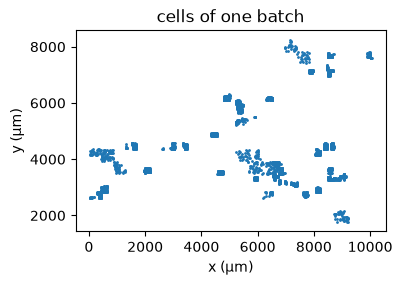

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.scatter(*batch["coords"].T, s=1)
ax.set(title="cells of one batch", xlabel="x (µm)", ylabel="y (µm)", aspect="equal");

## Throughput

A full pass over the collection, densifying every batch on the device.

In [7]:
import time

start = time.perf_counter()
for batch in loader:
    _ = batch["X"].to(device).to_dense()
elapsed = time.perf_counter() - start
print(f"streamed {loader.n_obs:,} cells in {elapsed:.1f}s → {loader.n_obs / elapsed:,.0f} cells/s")

streamed 596,017 cells in 1.2s → 508,780 cells/s


## Scaling up

- **More slides**: call {meth}`~spatialbatch.SpatialDatasetCollection.add_sdatas` again with new stores.
  Each becomes a new dataset of the collection; nothing is rewritten, since rows are mixed when sampling rather than on disk.
- **No pixels at all**: write a table-only collection with `images=(), labels=()`.
- **Pixels too**: the same collection streams tiles in {doc}`images` and tiles with expression in {doc}`multimodal`.